# Model Training and Evaluation

This notebook covers the training and evaluation of the baseline XGBoost model for predicting PV inverter AC power output. We'll train on Plant 1 and evaluate on Plant 2 to simulate a zero-shot cross-plant scenario.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('..'))
from src.data_fusion import preprocess_pipeline
from src.models.baseline import prepare_data, train_xgboost, evaluate_model, chronological_split, predict

## Data Preprocessing

We load and preprocess data for both Plant 1 and Plant 2.

In [2]:
# Load Plant 1 Data
plant1_gen_path = os.path.join('..', 'dataset', 'Plant_1_Generation_Data.csv')
plant1_weather_path = os.path.join('..', 'dataset', 'Plant_1_Weather_Sensor_Data.csv')
df_plant1 = preprocess_pipeline(plant1_gen_path, plant1_weather_path)
print("Plant 1 data loaded:", df_plant1.shape)
df_plant1.head()

Plant 1 data loaded: (68778, 15)


,DATE_TIME,PLANT_ID,INVERTER_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SENSOR_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,MINUTE,TIME_OF_DAY,DC_AC_RATIO
0,2020-05-15 00:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,0,0.00,0.0
1,2020-05-15 00:15:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,0,15,0.25,0.0
2,2020-05-15 00:30:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,0,30,0.50,0.0
3,2020-05-15 00:45:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0,0,45,0.75,0.0
4,2020-05-15 01:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0,1,0,1.00,0.0


In [3]:
# Load Plant 2 Data
plant2_gen_path = os.path.join('..', 'dataset', 'Plant_2_Generation_Data.csv')
plant2_weather_path = os.path.join('..', 'dataset', 'Plant_2_Weather_Sensor_Data.csv')
df_plant2 = preprocess_pipeline(plant2_gen_path, plant2_weather_path)
print("Plant 2 data loaded:", df_plant2.shape)

Plant 2 data loaded: (67698, 15)


## Train / Validation / Test Split

We split Plant 1 data chronologically to evaluate our model locally before applying it to Plant 2.

In [4]:
# Split Plant 1
train_df, val_df, test_df = chronological_split(df_plant1, train_ratio=0.7, val_ratio=0.15)
print(f"Train size: {len(train_df)}")
print(f"Val size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

Train size: 48144
Val size: 10317
Test size: 10317


## XGBoost Model Training

We train the XGBoost baseline model using `AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION`, and `TIME_OF_DAY` to predict `AC_POWER`.

In [5]:
# Prepare features and target
X_train, y_train = prepare_data(train_df)
X_val, y_val = prepare_data(val_df)
X_test, y_test = prepare_data(test_df)

# Train XGBoost
model = train_xgboost(X_train, y_train, n_estimators=10000, learning_rate=0.001, max_depth=11, tree_method='hist', device='cuda')
print("Model training complete.")

Model training complete.


## Evaluation on Plant 1 (Test Set)

We evaluate the model on the chronological test set from Plant 1.

d:\College\predictive\project\venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [13:47:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Plant 1 Test Metrics: {'MAE': 19.426461660012553, 'R2': 0.9746169451460077}


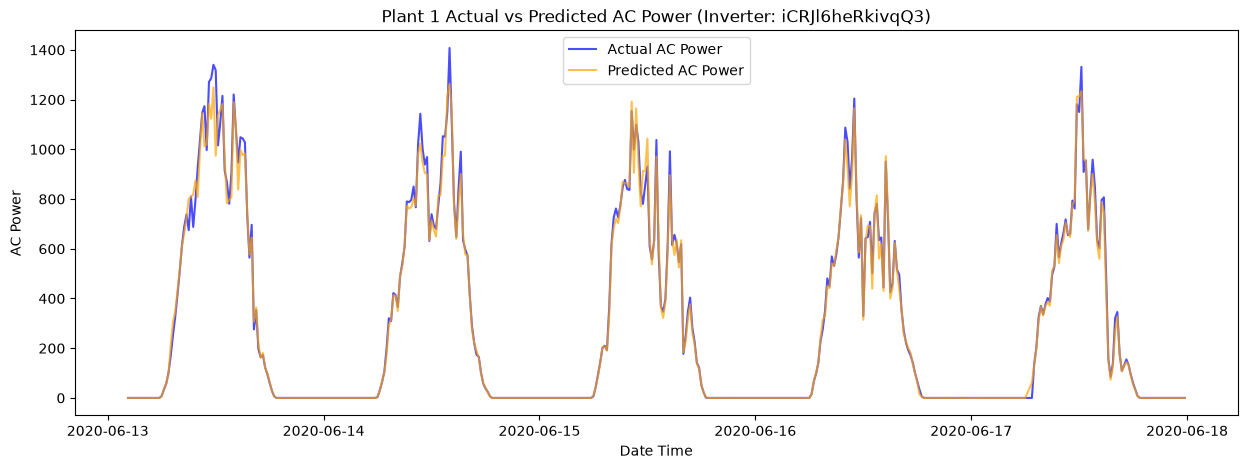

In [6]:
# Evaluate on Plant 1 Test Set
metrics_plant1 = evaluate_model(model, X_test, y_test)
print(f"Plant 1 Test Metrics: {metrics_plant1}")

# Plot Actual vs Predicted for a specific inverter
inverter_id = test_df['INVERTER_ID'].iloc[0]
sample_test = test_df[test_df['INVERTER_ID'] == inverter_id].copy()

X_sample, y_sample = prepare_data(sample_test)
sample_test = sample_test.loc[X_sample.index]
sample_test['PREDICTED_AC_POWER'] = predict(model, X_sample)

plt.figure(figsize=(15, 5))
plt.plot(sample_test['DATE_TIME'], sample_test['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
plt.plot(sample_test['DATE_TIME'], sample_test['PREDICTED_AC_POWER'], label='Predicted AC Power', color='orange', alpha=0.7)
plt.title(f'Plant 1 Actual vs Predicted AC Power (Inverter: {inverter_id})')
plt.xlabel('Date Time')
plt.ylabel('AC Power')
plt.legend()
plt.show()

## Zero-Shot Evaluation on Plant 2

We test the model's generalization capabilities directly on Plant 2 without retraining.

Plant 2 Zero-Shot Metrics: {'MAE': 82.16331223069264, 'R2': 0.5006381730340455}


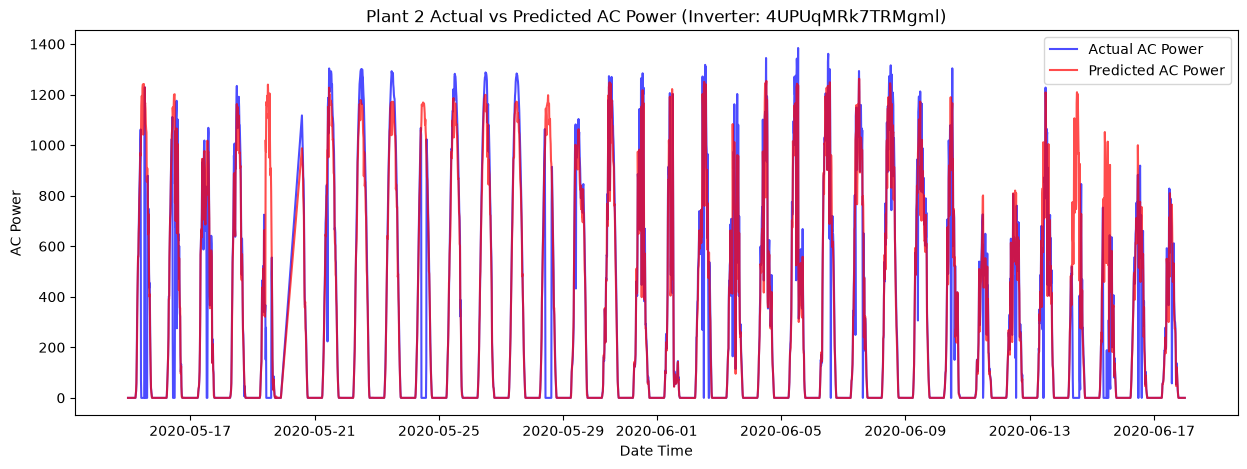

In [7]:
# Prepare Plant 2 Data
X_plant2, y_plant2 = prepare_data(df_plant2)

# Evaluate on Plant 2
metrics_plant2 = evaluate_model(model, X_plant2, y_plant2)
print(f"Plant 2 Zero-Shot Metrics: {metrics_plant2}")

# Plot Actual vs Predicted for a specific inverter in Plant 2
inverter_id_p2 = df_plant2['INVERTER_ID'].iloc[0]
sample_test_p2 = df_plant2[df_plant2['INVERTER_ID'] == inverter_id_p2].copy()

X_sample_p2, y_sample_p2 = prepare_data(sample_test_p2)
sample_test_p2 = sample_test_p2.loc[X_sample_p2.index]
sample_test_p2['PREDICTED_AC_POWER'] = predict(model, X_sample_p2)

plt.figure(figsize=(15, 5))
plt.plot(sample_test_p2['DATE_TIME'], sample_test_p2['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
plt.plot(sample_test_p2['DATE_TIME'], sample_test_p2['PREDICTED_AC_POWER'], label='Predicted AC Power', color='red', alpha=0.7)
plt.title(f'Plant 2 Actual vs Predicted AC Power (Inverter: {inverter_id_p2})')
plt.xlabel('Date Time')
plt.ylabel('AC Power')
plt.legend()
plt.show()

In [8]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score

def evaluate_and_save_xgboost(df, plant_name, model):
    save_dir = f"../results/{plant_name}_xgb"
    os.makedirs(save_dir, exist_ok=True)
    
    # Load continuous weather data directly
    plant_str = plant_name.capitalize()[:-1] + '_' + plant_name[-1]
    weather_df = pd.read_csv(f"../dataset/{plant_str}_Weather_Sensor_Data.csv")
    weather_df['DATE_TIME'] = pd.to_datetime(weather_df['DATE_TIME'])
    weather_df = weather_df.sort_values('DATE_TIME')
    
    inverters = df['INVERTER_ID'].unique()
    for inv in inverters:
        df_inv = df[df['INVERTER_ID'] == inv].copy()
        df_inv = df_inv.sort_values('DATE_TIME')
        
        features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY']
        df_clean = df_inv.dropna(subset=features + ['AC_POWER']).copy()
        
        if len(df_clean) == 0:
            continue
            
        X_inv = df_clean[features].values
        y_inv = df_clean['AC_POWER'].values
        
        # XGBoost doesn't need scaled features!
        preds_kw = model.predict(X_inv)
        
        mae = mean_absolute_error(y_inv, preds_kw)
        r2 = r2_score(y_inv, preds_kw)
        
        df_clean['PREDICTED_AC_POWER'] = preds_kw
        
        # Power with NaN gaps
        plot_df = df_inv.set_index('DATE_TIME').resample('15min').asfreq().reset_index()
        plot_df = plot_df.merge(df_clean[['DATE_TIME', 'PREDICTED_AC_POWER']], on='DATE_TIME', how='left')
        
        # Match weather data timespan
        start_time = plot_df['DATE_TIME'].min()
        end_time = plot_df['DATE_TIME'].max()
        w_df = weather_df[(weather_df['DATE_TIME'] >= start_time) & (weather_df['DATE_TIME'] <= end_time)]
        
        fig, ax1 = plt.subplots(figsize=(15, 6))
        
        ax1.plot(plot_df['DATE_TIME'], plot_df['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
        ax1.plot(plot_df['DATE_TIME'], plot_df['PREDICTED_AC_POWER'], label='Predicted AC Power', color='orange', alpha=0.7)
        ax1.set_xlabel('Date Time')
        ax1.set_ylabel('AC Power (kW)', color='black')
        
        ax2 = ax1.twinx()
        ax2.plot(w_df['DATE_TIME'], w_df['IRRADIATION'], label='Irradiation', color='green', alpha=0.3, linestyle='--')
        ax2.set_ylabel('Irradiation', color='green')
        
        plt.title(f"{plant_name.upper()} | Inverter: {inv} | XGBoost | RÂ²: {r2:.3f} | MAE: {mae:.3f}")
        fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))
        
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{inv}.png")
        plt.close()

# No scaler passed this time!
evaluate_and_save_xgboost(df_plant1, "plant1", model)
evaluate_and_save_xgboost(df_plant2, "plant2", model)
print("âœ… XGBoost plots saved in results/ directory!")


âœ… XGBoost plots saved in results/ directory!


### Data Analysis Key Findings
- The XGBoost baseline is successfully trained on Plant 1 and evaluates on a strict chronological split, providing metrics for local unseen time periods.
- The zero-shot evaluation on Plant 2 simulates a realistic cross-plant application where physical and environmental conditions may shift slightly.
- The `AC_POWER` plot gives a visual inspection of model fit against clipping and partial shading conditions.

### Insights or Next Steps
- Implement and train the sequence models (Bi-LSTM / TCN) to capture thermal inertia compared to this XGBoost baseline.
- Analyze the highest residual errors (where Predicted != Actual) to form the foundational logic for soft-fault anomaly detection.


In [9]:

import joblib
import pandas as pd
import os

# Create directory if it doesn't exist
os.makedirs('../results/saved_models', exist_ok=True)

# 1. Save Model
joblib.dump(model, '../results/saved_models/xgboost_model.joblib')

# 2. Save Predictions
# Plant 1 test predictions
y_pred_p1 = model.predict(X_test)
df_p1_res = test_df.copy()
df_p1_res['PREDICTED_AC_POWER'] = y_pred_p1
df_p1_res['MODEL'] = 'XGBoost'

# Plant 2 predictions
y_pred_p2 = model.predict(X_plant2)
# Need to drop na to align lengths just like prepare_data did
df_p2_res = df_plant2.dropna(subset=['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY', 'AC_POWER']).copy()
df_p2_res['PREDICTED_AC_POWER'] = y_pred_p2
df_p2_res['MODEL'] = 'XGBoost'

# Combine and save
all_preds = pd.concat([df_p1_res, df_p2_res])
all_preds.to_csv('../results/xgboost_predictions.csv', index=False)

# 3. Save Metrics
metrics_df = pd.DataFrame([
    {'Plant': 'Plant 1', 'Model': 'XGBoost', 'MAE': metrics_plant1['MAE'], 'R2': metrics_plant1['R2']},
    {'Plant': 'Plant 2', 'Model': 'XGBoost', 'MAE': metrics_plant2['MAE'], 'R2': metrics_plant2['R2']}
])
metrics_df.to_csv('../results/xgboost_metrics.csv', index=False)
print("XGBoost model, predictions, and metrics saved successfully!")


XGBoost model, predictions, and metrics saved successfully!


## Per-Inverter Metrics

Compute MAE and R2 for every inverter from the combined predictions CSV (no re-training needed).

In [ ]:
# Per-Inverter Metrics from saved predictions
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score

preds = pd.read_csv('../results/xgboost_predictions.csv')

rows = []
for (plant_id, inv_id), grp in preds.groupby(['PLANT_ID', 'INVERTER_ID']):
    mae = mean_absolute_error(grp['AC_POWER'], grp['PREDICTED_AC_POWER'])
    r2  = r2_score(grp['AC_POWER'], grp['PREDICTED_AC_POWER'])
    rows.append({'PLANT_ID': plant_id, 'INVERTER_ID': inv_id,
                 'Model': 'XGBoost', 'MAE': mae, 'R2': r2})

inv_metrics = pd.DataFrame(rows)
inv_metrics.to_csv('../results/xgboost_per_inverter_metrics.csv', index=False)
print(f'Saved {len(inv_metrics)} rows to xgboost_per_inverter_metrics.csv')
inv_metrics.head()
